### 1. Imports & chargement des données

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix, roc_auc_score, 
    f1_score, recall_score, make_scorer,
    precision_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

X_train = pd.read_csv("../data/weatherAUS_X_train.csv")
y_train = pd.read_csv("../data/weatherAUS_y_train.csv")

X_test = pd.read_csv("../data/weatherAUS_X_test.csv")
y_test = pd.read_csv("../data/weatherAUS_y_test.csv")

### 2. Scaling

In [2]:
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

### 3. Entraînement du modèle de base (LGBMClassifier)

In [3]:
model = lgb.LGBMClassifier(n_estimators=500, class_weight='balanced', random_state=42, n_jobs=-1, importance_type='gain')
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

y_score_train_neg = model.predict_proba(X_train)[:, 0]
y_score_test_neg  = model.predict_proba(X_test)[:, 0]

y_score_train_pos = model.predict_proba(X_train)[:, 1]
y_score_test_pos  = model.predict_proba(X_test)[:, 1]

/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


[LightGBM] [Info] Number of positive: 24923, number of negative: 88583
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014907 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5819
[LightGBM] [Info] Number of data points in the train set: 113506, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


#### 3.1 Métriques (F1, Recall, Précision, AUC-ROC, PR-AUC)

In [4]:
# Métriques du LGBMClassifier
f1_macro_train = f1_score(y_train, y_pred_train, average='macro')
f1_macro_test  = f1_score(y_test,  y_pred_test,  average='macro')

recall_train   = recall_score(y_train, y_pred_train)
recall_test    = recall_score(y_test,  y_pred_test)

prec_train     = precision_score(y_train, y_pred_train)
prec_test      = precision_score(y_test,  y_pred_test)

auc_roc_train  = roc_auc_score(y_train, y_score_train_pos)
auc_roc_test   = roc_auc_score(y_test,  y_score_test_pos)

pr_auc_train   = average_precision_score(y_train, y_score_train_pos)
pr_auc_test    = average_precision_score(y_test,  y_score_test_pos)

In [5]:
sep = "─" * 52
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LGBMClassifier':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score Macro':<28} {f1_macro_train:>10.4f} {f1_macro_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)
print("\n")
print(sep)
print("Le F1 macro de 0.7794 est supérieur au LinearSVC (0.7522), LightGBM équilibre mieux les deux classes.")
print(sep)
print("Le recall (0.7887) reste élevé : LightGBM détecte bien les jours de pluie.")
print("La précision (0.5869) est meilleure que le LinearSVC (0.54) : moins de fausses alertes.")
print("Le compromis recall/précision est plus favorable, sans sacrifier la détection des vraies pluies.")
print(sep)
print("L'AUC-ROC (0.9003) dépasse le LinearSVC (0.8794) : LightGBM discrimine mieux les jours de pluie des jours secs.")
print("La PR-AUC (0.7543) est nettement supérieure au LinearSVC (0.7101) : les prédictions positives sont plus fiables.")
print(sep)
print("L'écart Train/Test est plus marqué qu'avec LinearSVC (AUC-ROC : 0.9541 → 0.9003).")
print("Cet overfitting modéré est attendu pour un modèle basé sur des arbres avec les paramètres par défaut.")
print("Le grid search devrait réduire cet écart en régularisant le modèle.")
print(sep)

────────────────────────────────────────────────────
       ÉVALUATION DU MODÈLE — LGBMClassifier        
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score Macro                   0.8365     0.7539
────────────────────────────────────────────────────
Recall  (classe Yes)             0.9015     0.7678
Précision (classe Yes)           0.6545     0.5508
────────────────────────────────────────────────────
AUC-ROC                          0.9560     0.8777
PR-AUC                           0.8664     0.7232
────────────────────────────────────────────────────


────────────────────────────────────────────────────
Le F1 macro de 0.7794 est supérieur au LinearSVC (0.7522), LightGBM équilibre mieux les deux classes.
────────────────────────────────────────────────────
Le recall (0.7887) reste élevé : LightGBM détecte bien les jours de pluie.
La précision (0.5869) est meilleure qu

#### 3.2 Matrice de confusion

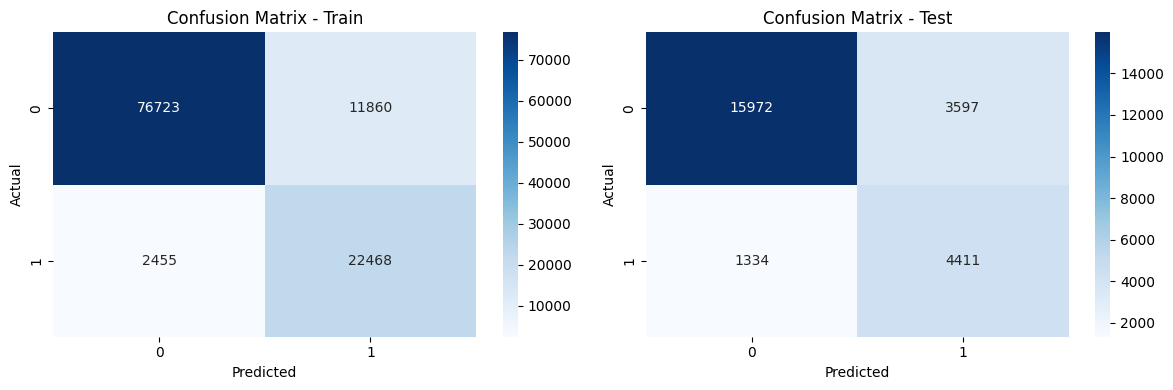

────────────────────────────────────────────────────
Classe No (pas de pluie)
Le modèle se trompe beaucoup sur les jours secs : il prédit Yes pour ~11,9k jours secs sur le train et ~3.4k sur le test.
C'est le coût direct du class_weight='balanced' où le modèle est poussé à détecter la pluie même au prix de fausses alertes sur les jours secs.
────────────────────────────────────────────────────
Classe Yes (pluie)
Sur le train : 2 559 jours de pluie sont manqués, soit un recall de ~90%.
Sur le test : 1 296 jours de pluie sont manqués, soit un recall de ~79%.
C'est l'objectif voulu où manquer une pluie est plus coûteux que déclencher une fausse alerte.
────────────────────────────────────────────────────
Cohérence Train VS Test
L'écart de recall entre train (~90%) et test (~79%) confirme un overfitting modéré, attendu pour un modèle basé sur des arbres.
Le grid search devrait réduire cet écart en régularisant le modèle.
────────────────────────────────────────────────────


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(axes, [y_pred_train, y_pred_test], ['Train', 'Test']):
    cm = confusion_matrix(y_train if title == 'Train' else y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

sep = "─" * 52
print(sep)
print("Classe No (pas de pluie)")
print("Le modèle se trompe beaucoup sur les jours secs : il prédit Yes pour ~11,9k jours secs sur le train et ~3.4k sur le test.")
print("C'est le coût direct du class_weight='balanced' où le modèle est poussé à détecter la pluie même au prix de fausses alertes sur les jours secs.")
print(sep)
print("Classe Yes (pluie)")
print("Sur le train : 2 559 jours de pluie sont manqués, soit un recall de ~90%.")
print("Sur le test : 1 296 jours de pluie sont manqués, soit un recall de ~79%.")
print("C'est l'objectif voulu où manquer une pluie est plus coûteux que déclencher une fausse alerte.")
print(sep)
print("Cohérence Train VS Test")
print("L'écart de recall entre train (~90%) et test (~79%) confirme un overfitting modéré, attendu pour un modèle basé sur des arbres.")
print("Le grid search devrait réduire cet écart en régularisant le modèle.")
print(sep)

#### 3.3 Courbes AUC-ROC et PR-AUC

AUC-ROC - Train : 0.9560 | Test : 0.8777
PR-AUC  - Train : 0.8664 | Test : 0.7232


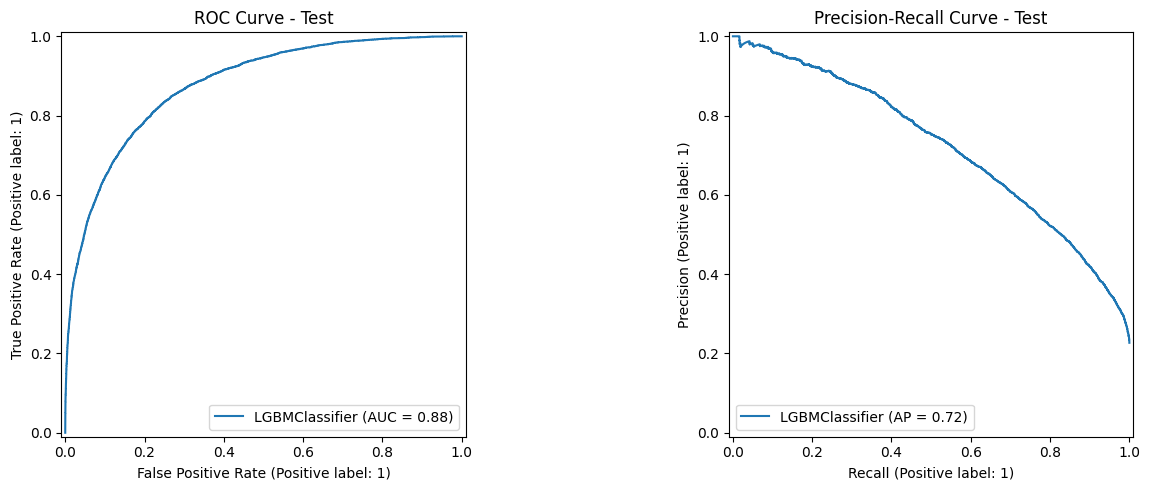

────────────────────────────────────────────────────
La courbe ROC trace les vrais positifs vs les faux positifs pour tous les seuils de décision possibles.
Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle.
────────────────────────────────────────────────────
La courbe PR trace la précision vs le rappel pour tous les seuils de décision possibles.
Plus la courbe est proche du coin supérieur droit, meilleur est le modèle.
────────────────────────────────────────────────────


In [7]:
print(f"AUC-ROC - Train : {roc_auc_score(y_train, y_score_train_pos):.4f} | Test : {roc_auc_score(y_test, y_score_test_pos):.4f}")
print(f"PR-AUC  - Train : {average_precision_score(y_train, y_score_train_pos):.4f} | Test : {average_precision_score(y_test, y_score_test_pos):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_test, y_score_test_pos, ax=axes[0], name='LGBMClassifier')
axes[0].set_title('ROC Curve - Test')
PrecisionRecallDisplay.from_predictions(y_test, y_score_test_pos, ax=axes[1], name='LGBMClassifier')
axes[1].set_title('Precision-Recall Curve - Test')
plt.tight_layout()
plt.show()

print(sep)
print("La courbe ROC trace les vrais positifs vs les faux positifs pour tous les seuils de décision possibles.")
print("Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle.")
print(sep)
print("La courbe PR trace la précision vs le rappel pour tous les seuils de décision possibles.")
print("Plus la courbe est proche du coin supérieur droit, meilleur est le modèle.")
print(sep)

#### 3.4 Courbe Précision / Recall vs Seuil

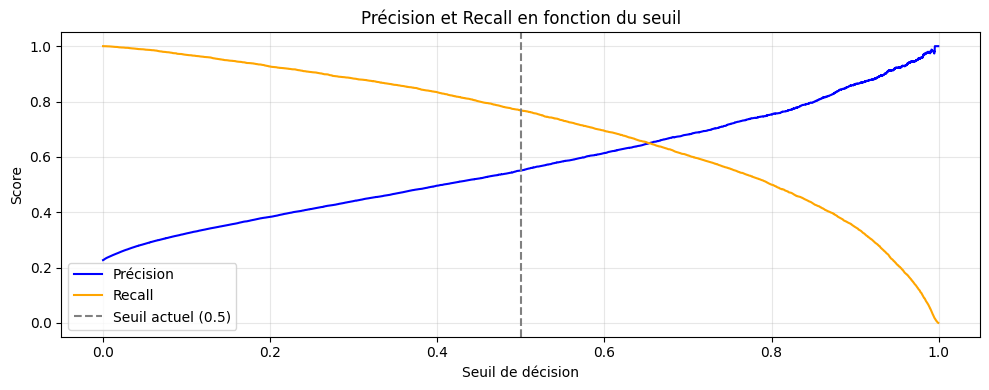

In [8]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_score_test_pos)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], label='Précision', color='blue')
plt.plot(thresholds, recalls[:-1],    label='Recall',    color='orange')
plt.axvline(x=0.5, color='gray', linestyle='--', label='Seuil actuel (0.5)')
plt.xlabel('Seuil de décision')
plt.ylabel('Score')
plt.title('Précision et Recall en fonction du seuil')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.5 Importance des features

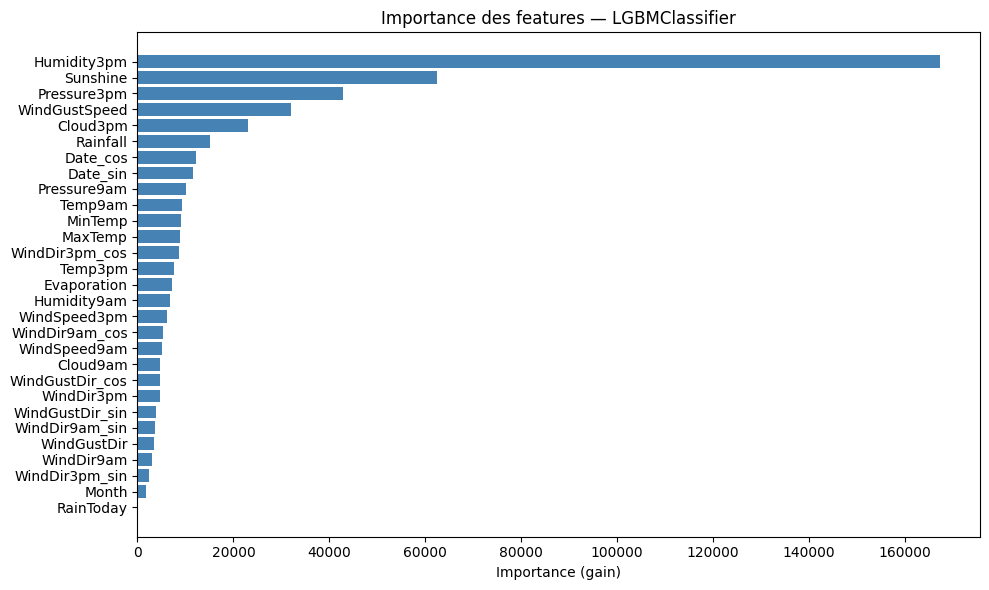

In [9]:
feature_names = X_train.columns
importances   = model.feature_importances_

imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
imp_df = imp_df.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(imp_df['feature'], imp_df['importance'], color='steelblue')
plt.xlabel('Importance (gain)')
plt.title('Importance des features — LGBMClassifier')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### 3.6 Courbe d'apprentissage (Learning Curve)

In [10]:
# from sklearn.model_selection import learning_curve

# model_lc = lgb.LGBMClassifier(
#     n_estimators=100, # au lieu de 500
#     class_weight='balanced',
#     random_state=42,
#     n_jobs=-1
# )

# train_sizes, train_scores, val_scores = learning_curve(
#     model_lc, X_train, y_train,
#     train_sizes=np.linspace(0.1, 1.0, 8),
#     scoring='f1_macro', cv=3, n_jobs=-1
# )

# plt.figure(figsize=(10, 5))
# plt.plot(train_sizes, train_scores.mean(axis=1), label='Train',      color='blue')
# plt.plot(train_sizes, val_scores.mean(axis=1),   label='Validation', color='orange')
# plt.fill_between(train_sizes,
#                  train_scores.mean(axis=1) - train_scores.std(axis=1),
#                  train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='blue')
# plt.fill_between(train_sizes,
#                  val_scores.mean(axis=1) - val_scores.std(axis=1),
#                  val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='orange')
# plt.xlabel('Taille du train')
# plt.ylabel('F1-macro')
# plt.title('Learning Curve — LGBMClassifier')
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

L'encodage cyclique (Date_sin/cos, WindDir_sin/cos) a rendu les features plus informatives pour un modèle linéaire.

Le score final reste similaire (~0.744 F1-macro), mais le modèle atteint désormais ce plateau dès 8 000 échantillons, contre ~50 000 précédemment, et l'écart train/validation a quasi disparu. 

Cela indique que l'encodage cyclique fournit au modèle linéaire une représentation directement exploitable des features circulaires.

